In [1]:
import torch

torch.manual_seed(42)

# 固定的真实参数：用于生成数据，不参与训练更新
true_w = torch.tensor([2.0, -3.4])
true_b = 4.2

# 1000 条样本，每条有 2 个特征
features = torch.randn(1000, 2)

# 理想结果 + 标准差为 0.01 的噪声
ideal_y = features @ true_w + true_b
noise = torch.randn_like(ideal_y) * 0.01
labels = (ideal_y + noise).reshape(-1, 1)

assert features.shape == (1000, 2)
assert labels.shape == (1000, 1)

print("features.shape:", features.shape)
print("labels.shape:", labels.shape)

features.shape: torch.Size([1000, 2])
labels.shape: torch.Size([1000, 1])


In [2]:
"""
沿用之前生成的 features、labels，完成三件事：
1. 用 data_iter(128, features, labels) 遍历数据，记录每批实际大小，打印批次数、最后一批大小、样本总数。这里只读取数据，还没有更新参数。
2. 取一批，初始化 w、b，计算预测；用断言检查：
assert predictions.shape == y_batch.shape
3. 在 CPU 上，对长度为 10000 的两个向量分别做“Python 循环逐元素相加”和“一次 a + b”。用 time.perf_counter() 在操作前后计时，并用 torch.allclose() 检查结果一致。perf_counter() 返回适合测量耗时的秒数；只做直观比较，不追求精确性能结论，也不需要重写教材的计时器类。
"""

import random
import time

def data_iter(batch_size, features, labels):
    num_examples = len(features)
    indices = list(range(num_examples))
    random.shuffle(indices)

    for start in range(0, num_examples, batch_size):
        batch_indices = indices[start:start + batch_size]
        yield features[batch_indices], labels[batch_indices]

# 1. 检查每一批
batch_sizes = []
for X_batch, y_batch in data_iter(128, features, labels):
    assert len(X_batch) == len(y_batch)
    batch_sizes.append(len(X_batch))

print("批次数: ", len(batch_sizes))
print("最后一批大小: ", batch_sizes[-1])
print("样本总数: ", sum(batch_sizes))

# 2. 取一批, 初始化待训练参数并预测
X_batch, y_batch = next(data_iter(128, features, labels))
w = (torch.randn(2, 1) * 0.01).requires_grad_()
b = torch.zeros(1, requires_grad=True)

predictions = X_batch @ w + b
assert predictions.shape == y_batch.shape

# 3. Python 循环与整批相加
a = torch.randn(10000)
c = torch.randn(10000)
loop_result = torch.empty_like(a)

print("X_batch.shape:", X_batch.shape)
print("predictions.shape:", predictions.shape)
print("y_batch.shape:", y_batch.shape)

start = time.perf_counter()
for i in range(a.numel()):
    loop_result[i] = a[i] + c[i]
loop_time = time.perf_counter() - start

start = time.perf_counter()
vector_result = a + c
vector_time = time.perf_counter() - start

assert torch.allclose(loop_result, vector_result)
print("循环耗时: ", loop_time)
print("整批相加耗时: ", vector_time)

批次数:  8
最后一批大小:  104
样本总数:  1000
X_batch.shape: torch.Size([128, 2])
predictions.shape: torch.Size([128, 1])
y_batch.shape: torch.Size([128, 1])
循环耗时:  0.11464230006095022
整批相加耗时:  8.160003926604986e-05


In [3]:
def linreg(X, w, b):
    return X @ w + b  # TODO：返回预测值


def squared_loss(predictions, targets):
    assert predictions.shape == targets.shape
    return (predictions - targets)**2 / 2  # TODO：返回逐样本的半平方损失，不在这里取平均


def sgd(params, lr):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad  # TODO：原地更新参数，不再除以批量大小
            param.grad.zero_()  # TODO：清零该参数的梯度


# 重新初始化待训练参数，不改变 true_w、true_b
w = torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b = torch.zeros(1, requires_grad=True)

lr = 0.03
batch_size = 128
num_epochs = 30
loss_history = []

for epoch in range(num_epochs):
    for X_batch, y_batch in data_iter(batch_size, features, labels):
        predictions = linreg(X_batch, w, b)  # TODO：调用模型
        losses = squared_loss(predictions, y_batch) # TODO：调用逐样本损失函数
        loss = losses.mean()

        loss.backward()  # TODO：反向传播
        sgd([w, b], lr)  # TODO：调用手写 SGD，更新 w、b 并清零梯度

    with torch.no_grad():
        train_predictions = linreg(features, w, b)
        train_loss = squared_loss(train_predictions, labels).mean()
        loss_history.append(train_loss.item())

    print(f"epoch {epoch + 1}, loss {loss_history[-1]:.6f}")

print("学到的 w:", w.detach().reshape(-1))
print("真实的 w:", true_w)
print("学到的 b:", b.detach())
print("真实的 b:", true_b)

epoch 1, loss 9.960233
epoch 2, loss 6.241437
epoch 3, loss 3.910571
epoch 4, loss 2.451029
epoch 5, loss 1.539633
epoch 6, loss 0.969643
epoch 7, loss 0.609911
epoch 8, loss 0.383019
epoch 9, loss 0.240991
epoch 10, loss 0.151605
epoch 11, loss 0.095548
epoch 12, loss 0.060266
epoch 13, loss 0.038058
epoch 14, loss 0.024055
epoch 15, loss 0.015186
epoch 16, loss 0.009597
epoch 17, loss 0.006084
epoch 18, loss 0.003871
epoch 19, loss 0.002469
epoch 20, loss 0.001580
epoch 21, loss 0.001018
epoch 22, loss 0.000664
epoch 23, loss 0.000439
epoch 24, loss 0.000297
epoch 25, loss 0.000207
epoch 26, loss 0.000149
epoch 27, loss 0.000113
epoch 28, loss 0.000090
epoch 29, loss 0.000075
epoch 30, loss 0.000066
学到的 w: tensor([ 1.9965, -3.3969])
真实的 w: tensor([ 2.0000, -3.4000])
学到的 b: tensor([4.1968])
真实的 b: 4.2


权重误差（学习值 - 真实值）: tensor([-0.0035,  0.0031])
偏置误差（学习值 - 真实值）: tensor([-0.0032])


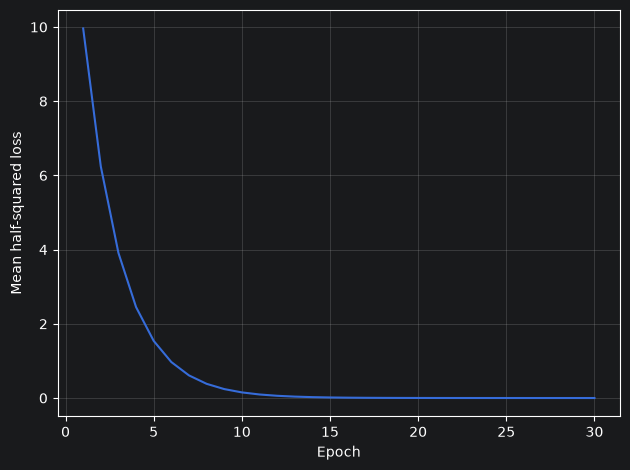

In [4]:
import matplotlib.pyplot as plt

with torch.no_grad():
    w_error = w.reshape(-1) - true_w
    b_error = b - true_b

print("权重误差（学习值 - 真实值）:", w_error)
print("偏置误差（学习值 - 真实值）:", b_error)

plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

dataset = TensorDataset(features, labels)
loader = DataLoader(dataset, batch_size=128, shuffle=True)

# 初始化只做一次，放在训练循环外
model = nn.Sequential(nn.Linear(2, 1))
nn.init.normal_(model[0].weight, mean=0.0, std=0.01)
nn.init.zeros_(model[0].bias)

loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.03)

num_epochs = 30
framework_loss_history = []

for epoch in range(num_epochs):
    for batch_id, (X_batch, y_batch) in enumerate(loader):
        optimizer.zero_grad()  # TODO：清除旧梯度

        predictions = model(X_batch)  # TODO：通过 model 预测
        assert predictions.shape == y_batch.shape
        loss = loss_fn(predictions, y_batch) / 2  # TODO：计算平均半平方损失

        loss.backward()  # TODO：反向传播

        if epoch == 0 and batch_id == 0:
            print("权重: ", model[0].weight)# TODO：打印权重和偏置的梯度及其形状
            print("偏置: ", model[0].bias)
            print("权重梯度: ", model[0].weight.grad)
            print("偏置梯度: ", model[0].bias.grad)
            print("权重梯度形状: ", model[0].weight.grad.shape)
            print("偏置梯度形状: ", model[0].bias.grad.shape)

        optimizer.step()  # TODO：更新参数

    with torch.no_grad():
        train_predictions = model(features)
        train_loss = loss_fn(train_predictions, labels) / 2 # TODO：全训练集平均半平方损失
        framework_loss_history.append(train_loss.item())

    print(
        f"epoch {epoch + 1}, "
        f"loss {framework_loss_history[-1]:.6f}"
    )

权重:  Parameter containing:
tensor([[-0.0083, -0.0161]], requires_grad=True)
偏置:  Parameter containing:
tensor([0.], requires_grad=True)
权重梯度:  tensor([[-1.4064,  4.0102]])
偏置梯度:  tensor([-3.6658])
权重梯度形状:  torch.Size([1, 2])
偏置梯度形状:  torch.Size([1])
epoch 1, loss 9.939084
epoch 2, loss 6.227985
epoch 3, loss 3.906678
epoch 4, loss 2.453727
epoch 5, loss 1.543946
epoch 6, loss 0.970294
epoch 7, loss 0.611229
epoch 8, loss 0.384751
epoch 9, loss 0.243139
epoch 10, loss 0.153064
epoch 11, loss 0.096547
epoch 12, loss 0.060947
epoch 13, loss 0.038461
epoch 14, loss 0.024333
epoch 15, loss 0.015398
epoch 16, loss 0.009746
epoch 17, loss 0.006185
epoch 18, loss 0.003936
epoch 19, loss 0.002506
epoch 20, loss 0.001607
epoch 21, loss 0.001036
epoch 22, loss 0.000674
epoch 23, loss 0.000446
epoch 24, loss 0.000301
epoch 25, loss 0.000209
epoch 26, loss 0.000150
epoch 27, loss 0.000114
epoch 28, loss 0.000090
epoch 29, loss 0.000075
epoch 30, loss 0.000066


学到的权重: tensor([ 1.9965, -3.3969])
权重误差: tensor([-0.0035,  0.0031])
学到的偏置: tensor([4.1968])
偏置误差: tensor([-0.0032])
损失一致性检查通过: 6.610744458157569e-05


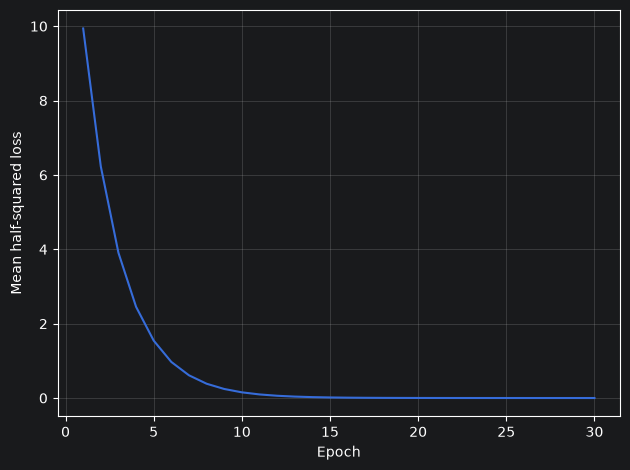

In [6]:
import matplotlib.pyplot as plt

with torch.no_grad():
    learned_w = model[0].weight.detach().reshape(-1)
    learned_b = model[0].bias.detach()

    print("学到的权重:", learned_w)
    print("权重误差:", learned_w - true_w)
    print("学到的偏置:", learned_b)
    print("偏置误差:", learned_b - true_b)

    predictions = model(features)
    assert predictions.shape == labels.shape

    manual_loss = ((predictions - labels) ** 2 / 2).mean()
    framework_loss = loss_fn(predictions, labels) / 2
    assert torch.allclose(manual_loss, framework_loss)
    print("损失一致性检查通过:", framework_loss.item())

plt.plot(range(1, len(framework_loss_history) + 1),
         framework_loss_history)
plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
torch.manual_seed(42)

initial_weight = torch.randn(1, 2) * 0.01
initial_bias = torch.zeros(1)
dataset = TensorDataset(features, labels)

learning_rates = [0.003, 0.03, 0.3]

In [8]:
def run_experiment(lr):
    model = nn.Sequential(nn.Linear(2, 1))
    with torch.no_grad():
        model[0].weight.copy_(initial_weight)
        model[0].bias.copy_(initial_bias)

    g = torch.Generator().manual_seed(123)
    loader = DataLoader(
        dataset, batch_size=128, shuffle=True,
        generator=g, num_workers=0,
    )

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []

    # epoch 0：尚未更新任何参数
    with torch.no_grad():
        initial_loss = loss_fn(model(features), labels) / 2
        history.append(initial_loss.item())

    for epoch in range(30):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()  # TODO：清除旧梯度
            predictions = model(X_batch)  # TODO：预测
            assert predictions.shape == y_batch.shape
            loss = loss_fn(predictions, y_batch) / 2  # TODO：平均半平方损失
            loss.backward()  # TODO：反向传播
            optimizer.step()  # TODO：更新参数

        with torch.no_grad():
            train_loss = loss_fn(model(features), labels) / 2
            history.append(train_loss.item())

    return {
        "lr": lr,
        "history": history,
        "weight": model[0].weight.detach().reshape(-1).clone(),
        "bias": model[0].bias.detach().clone(),
    }


results = [run_experiment(lr) for lr in learning_rates]

学习率: 0.003
初始损失: 15.87874031
最终损失: 3.99188280
权重误差: tensor([-1.0932,  1.6931])
偏置误差: tensor([-2.0761])

学习率: 0.03
初始损失: 15.87874031
最终损失: 0.00006623
权重误差: tensor([-0.0035,  0.0031])
偏置误差: tensor([-0.0033])

学习率: 0.3
初始损失: 15.87874031
最终损失: 0.00004992
权重误差: tensor([-1.4186e-05,  7.5340e-05])
偏置误差: tensor([0.0002])



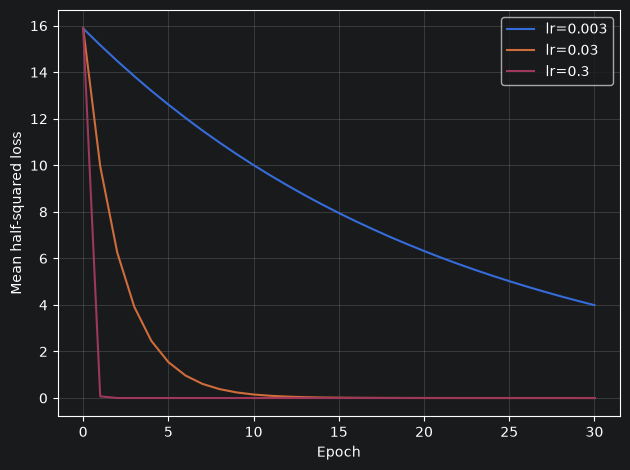

In [9]:
import matplotlib.pyplot as plt

starts = [r["history"][0] for r in results]
assert all(abs(value - starts[0]) < 1e-6 for value in starts)

for r in results:
    history = r["history"]
    assert len(history) == 31

    print(f"学习率: {r['lr']}")
    print(f"初始损失: {history[0]:.8f}")
    print(f"最终损失: {history[-1]:.8f}")
    print("权重误差:", r["weight"] - true_w)
    print("偏置误差:", r["bias"] - true_b)
    print()

    plt.plot(range(len(history)), history, label=f"lr={r['lr']}")

plt.xlabel("Epoch")
plt.ylabel("Mean half-squared loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()